# Diagnóstico de cancro da mama — Protótipo do agente

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

Junta as peças dos notebooks anteriores num protótipo de agente para o paciente:

1. o modelo (MobileNetV2 do notebook 01) classifica a ecografia;
2. o Grad-CAM (notebook 03) mostra onde o modelo olhou;
3. **Human-in-the-Loop:** se o modelo prevê maligno ou não tem certeza, o caso vai sempre para o médico e nada é comunicado ao paciente como resultado;
4. **Human-on-the-Loop:** os outros casos são decididos pelo sistema, mas ficam num log que o médico revê e corrige;
5. um chatbot responde às perguntas do paciente com base em documentos médicos (RAG), usando o LLM do IAedu.

Não é uma aplicação: é um protótipo para mostrar e avaliar o funcionamento.

## 1. Configuração

- `MALIGNANT_TARGET`: fração dos cancros que tem de chegar ao médico (ver secção 2).
- `CHAT_INTERACTIVE = True` abre uma conversa com `input()` na secção 5; com `False` só corre as perguntas de exemplo.
- O chatbot precisa de um ficheiro `.env` com a chave do IAedu (ver o README) e dos documentos em `docs/rag/` (issue #5). Sem eles, as secções 2 a 4 funcionam na mesma.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, MODELS_PATH, RAG_PATH, RESULTS_PATH
from src.gpu import setup_gpu

setup_gpu()

IMG_SIZE = 128
MALIGNANT_TARGET = 0.95
CHAT_INTERACTIVE = False
LOG_PATH = RESULTS_PATH / "agent_log.csv"   # fora do git

A treinar na GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Modelo e regra para chamar o médico

Um caso vai para o médico se o modelo prevê **maligno** ou se a probabilidade da classe prevista (a **confiança**) é menor do que um limiar. O notebook 03 mostrou porque a confiança não chega sozinha: o modelo falha alguns cancros com mais de 97% de certeza.

O limiar é o menor que faz chegar ao médico pelo menos `MALIGNANT_TARGET` dos cancros do conjunto de **validação** (`choose_threshold` em `src/agent.py`). Um limiar maior apanha mais cancros, mas manda mais casos ao médico. Escolhe-se na validação e não no teste, para o teste mostrar honestamente como a regra funciona em imagens novas.

In [2]:
import numpy as np
from src.agent import choose_threshold, referral_summary
from src.data import load_dataset
from src.explain import GradCAM, load_model

_, x_val, x_test, _, y_val, y_test, names_test = load_dataset(DATA_PATH, size=IMG_SIZE, test_names=True)
model = load_model(MODELS_PATH / "mobilenet.keras")
explainer = GradCAM(model)
probs_val = model.predict(x_val, verbose=0)
probs_test = model.predict(x_test, verbose=0)

threshold = choose_threshold(probs_val, y_val, MALIGNANT_TARGET)
print(f"Limiar escolhido na validação: {threshold:.2f}\n")
for name, probs, y in [("validação", probs_val, y_val), ("teste", probs_test, y_test)]:
    print(name, referral_summary(probs, y, threshold))

Limiar escolhido na validação: 0.88

validação {'enviadas ao médico': '71 de 127 (56%)', 'malignos que chegam ao médico': '36 de 37', 'erros decididos sem médico': '6 de 56'}
teste {'enviadas ao médico': '82 de 149 (55%)', 'malignos que chegam ao médico': '36 de 39', 'erros decididos sem médico': '8 de 67'}


## 3. Analisar uma ecografia

`analyse` faz o que o agente faz quando recebe uma imagem: classifica-a, calcula o Grad-CAM, decide para onde vai e mostra a mensagem para o paciente. Os exemplos são imagens do **teste** (que o modelo nunca viu): uma em que o modelo prevê maligno, uma em que não tem certeza e uma decidida sem médico.

Os textos para o paciente são provisórios (issue #10) e estão em `TEXTS`, em `src/agent.py`.

Olá. Este protótipo analisa uma ecografia mamária com um modelo de inteligência artificial e responde a perguntas sobre o resultado.


/home/httpirsh/Documentos/Mestrado/IACH/Projeto/.venv/lib64/python3.11/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 128, 128, 1))
  warnings.warn(msg)


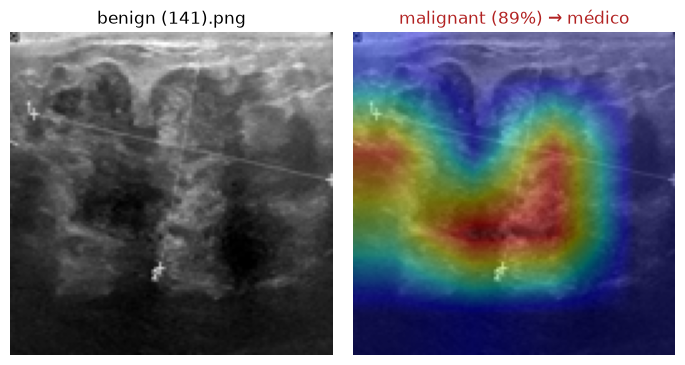

Motivo: o modelo prevê maligno

Para o paciente:
O resultado precisa de ser visto por um médico, por isso o seu exame vai ser revisto antes de lhe ser comunicado qualquer resultado. Isto não quer dizer que haja um problema: o modelo pede ajuda sempre que não tem certeza ou que vê algo que deve ser confirmado.

Isto não é um diagnóstico. Só o seu médico pode interpretar o exame e decidir os próximos passos.
As zonas a vermelho são as que mais pesaram na decisão do modelo; não mostram necessariamente uma lesão.


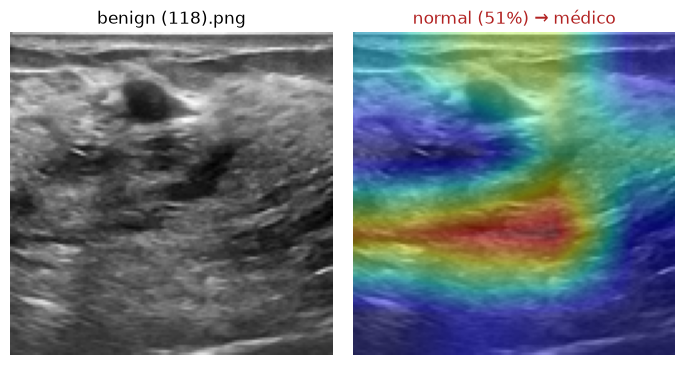

Motivo: confiança (51%) abaixo do limiar (88%)

Para o paciente:
O resultado precisa de ser visto por um médico, por isso o seu exame vai ser revisto antes de lhe ser comunicado qualquer resultado. Isto não quer dizer que haja um problema: o modelo pede ajuda sempre que não tem certeza ou que vê algo que deve ser confirmado.

Isto não é um diagnóstico. Só o seu médico pode interpretar o exame e decidir os próximos passos.
As zonas a vermelho são as que mais pesaram na decisão do modelo; não mostram necessariamente uma lesão.


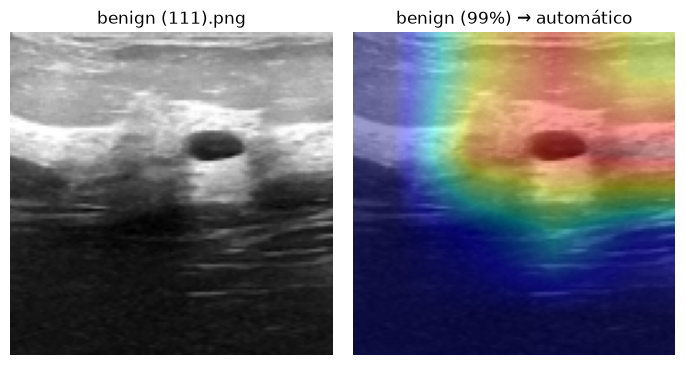

Motivo: benign com confiança alta (99%)

Para o paciente:
O modelo classificou a imagem como benigno, com confiança de 99%. Este resultado fica registado e pode ser revisto pelo seu médico.

Isto não é um diagnóstico. Só o seu médico pode interpretar o exame e decidir os próximos passos.
As zonas a vermelho são as que mais pesaram na decisão do modelo; não mostram necessariamente uma lesão.


In [3]:
from src.agent import AUTOMATIC, TEXTS, decide, patient_message, show_case
from src.data import load_image


def analyse(file, show=True):
    image = load_image(file, IMG_SIZE)
    cam, probs = explainer(image)
    decision = decide(probs, threshold)
    if show:
        show_case(image, cam, decision, title=Path(file).name)
        print("Motivo:", decision["motivo"])
        print("\nPara o paciente:\n" + patient_message(decision) + "\n" + TEXTS["heatmap"])
    return decision


pred, conf = probs_test.argmax(axis=1), probs_test.max(axis=1)
examples = [np.where(pred == 2)[0][0],                                # prevê maligno
            np.where((pred != 2) & (conf < threshold))[0][0],         # não tem certeza
            np.where((pred != 2) & (conf >= threshold))[0][0]]        # decidido sem médico
print(TEXTS["boas_vindas"])
for i in examples:
    decision = analyse(DATA_PATH / names_test[i])

## 4. Human-on-the-Loop: o log e a revisão do médico

Passam-se todas as imagens de teste pelo agente. Cada caso fica no log (`results/agent_log.csv`, fora do git) com a decisão e para onde foi. O médico revê os casos **automáticos**, isto é, os que ninguém viu, e corrige-os com `review_case`.

Aqui sabemos a classe verdadeira, por isso podemos ver quantos casos automáticos estão errados: são estes que o médico tem de apanhar na revisão.

In [4]:
from src.agent import log_case, read_log, review_case
from src.data import label_from_name

LOG_PATH.unlink(missing_ok=True)   # começar um log novo
for name, probs in zip(names_test, probs_test):   # as mesmas probabilidades da tabela da secção 2
    log_case(LOG_PATH, name, decide(probs, threshold))

log = read_log(LOG_PATH)
log["classe_real"] = log["imagem"].map(label_from_name)   # só para avaliar: o agente não a vê
automatic = log[log["encaminhamento"] == AUTOMATIC]
print(log["encaminhamento"].value_counts().to_string(), "\n")
print(f"Casos automáticos errados ({(automatic['classe_prevista'] != automatic['classe_real']).sum()}):")
automatic[automatic["classe_prevista"] != automatic["classe_real"]]

encaminhamento
médico        82
automático    67 

Casos automáticos errados (8):


,data,imagem,classe_prevista,confianca,encaminhamento,revisto,classe_medico,classe_real
19,2026-11-09T20:38:42,benign (194).png,normal,0.922,automático,False,,benign
24,2026-11-09T20:38:42,benign (212).png,normal,0.913,automático,False,,benign
50,2026-11-09T20:38:42,benign (335).png,normal,0.990,automático,False,,benign
52,2026-11-09T20:38:42,benign (344).png,normal,0.968,automático,False,,benign
53,2026-11-09T20:38:42,benign (349).png,normal,0.996,automático,False,,benign
86,2026-11-09T20:38:42,malignant (111).png,benign,0.993,automático,False,,malignant
91,2026-11-09T20:38:42,malignant (148).png,benign,0.975,automático,False,,malignant
92,2026-11-09T20:38:42,malignant (15).png,benign,0.968,automático,False,,malignant


O médico revê um caso: indica a classe correta (a mesma, se concordar). Aqui simula-se o médico com a classe verdadeira de um cancro que o sistema tinha decidido sozinho.

In [5]:
missed = automatic[(automatic["classe_real"] == "malignant") & (automatic["classe_prevista"] != "malignant")]
if len(missed):
    case = missed.iloc[0]
    print(review_case(LOG_PATH, case["imagem"], case["classe_real"]).to_string())

pending = read_log(LOG_PATH).query("encaminhamento == @AUTOMATIC and not revisto")
print(f"\nCasos automáticos ainda por rever: {len(pending)}")

                   data               imagem classe_prevista  confianca encaminhamento  revisto classe_medico
86  2026-11-09T20:38:42  malignant (111).png          benign      0.993     automático     True     malignant

Casos automáticos ainda por rever: 66


## 5. Chatbot (RAG + LLM do IAedu)

O chatbot (`src/rag.py`) procura os excertos dos documentos de `docs/rag/` mais parecidos com a pergunta e envia-os ao LLM com a pergunta e as regras: linguagem simples, citar a fonte, nunca dar um diagnóstico, sugerir falar com o médico. Também recebe o resultado do caso, exceto quando o caso foi para o médico: aí o LLM só sabe que o exame vai ser revisto, para a classe não chegar ao paciente antes de o médico a ver.

Primeiro mostra-se só a pesquisa (que excertos seriam usados), que não precisa do LLM.

In [6]:
from src.agent import case_for_chat
from src.llm import IAedu, iaedu_configured
from src.rag import Retriever, answer, load_documents

documents = load_documents(RAG_PATH)
print(f"{len(documents)} documentos em docs/rag/")
retriever = Retriever(documents) if documents else None
llm = IAedu() if iaedu_configured() else None
if retriever is None:
    print("Sem documentos: o chatbot fica à espera da issue #5.")
if llm is None:
    print("Sem .env do IAedu: mostra-se só a pesquisa nos documentos.")

questions = ["O que quer dizer um resultado benigno?",
             "Isto quer dizer que tenho cancro?",
             "Quais são os próximos passos depois da ecografia?"]
case = case_for_chat(decide(probs_test[examples[2]], threshold))
if retriever is not None:
    for question in questions:
        print(f"\n### {question}")
        for name, text, score in retriever.search(question, k=3):
            print(f"  {score:.2f}  {name}: {text[:100]!r}")
        if llm is not None:
            reply, _ = answer(question, retriever, llm, case=case)
            print("\n" + reply)

0 documentos em docs/rag/
Sem documentos: o chatbot fica à espera da issue #5.


Conversa livre (com `CHAT_INTERACTIVE = True`). Escrever `sair` para terminar.

In [7]:
if CHAT_INTERACTIVE and retriever is not None and llm is not None:
    llm.new_conversation()
    print(TEXTS["boas_vindas"], "\n" + TEXTS["aviso"])
    while (question := input("Pergunta: ").strip()).lower() not in ("sair", ""):
        reply, passages = answer(question, retriever, llm, case=case)
        print(reply, "\n   fontes:", sorted({name for name, _, _ in passages}))

## 6. Estado

- Feito: classificação, Grad-CAM, regra para chamar o médico escolhida na validação, log e revisão do médico, pesquisa nos documentos e ligação ao LLM do IAedu.
- Falta: os documentos médicos (#5), os textos finais para o paciente (#10) e a avaliação das respostas do chatbot com perguntas de teste (#8, #9).